# 14조 중도탈락 고위험 학과 예측 (신효주 최종 노트북)
- 원본 `14조_신효주.ipynb`(초기 설계: H1~H4, 범위 50,544행, 재계산 비율)의 구조를 살려, 팀이 결과 전에 고정한 최종 설계(`00_문제정의_가설.md` v3)에 맞춘 사본이다.
- 바뀐 점: 범위에 폐교 제외 추가(50,081행), y는 공시 비율 사용(재계산과 차이 최대 0.005%p), 가설은 A(전국 구조)와 B(한국외대), 예측은 작년 고위험 학과 수 k만큼 지원할 때 정밀도로 비교, R2(사유 구성)는 폐기.
- 실행: CSV를 올린 뒤 **런타임 → 다시 시작 및 모두 실행**. 핵심 수치는 assert로 팀 정본과 대조한다.

## 1. 수집

In [1]:
import os, glob
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix
import warnings; warnings.filterwarnings('ignore')

RANDOM_STATE = 42
MIN_ENROLL = 30          # 민감도: 10, 50
HUFS_CODE = 192          # 한국외국어대학교 (사이버한국외국어대학교 332와 구분)
B_SUBFIELDS = ['기타유럽어・문학', '기타아시아어・문학']   # 가운데 점은 데이터 그대로 복사한 문자
REASONS = ['미등록', '미복학', '자퇴', '학사경고', '학생활동', '유급제적', '재학연한초과', '기타']
KEY = ['공시연도', '학교코드', '학과코드']
TRAIN_YEARS, TEST_YEAR = [2024, 2025], 2026

collect_record = {
    '데이터명': '교육부_대학알리미_중도탈락 학생 현황_대학_학과별',
    'URL': 'https://www.data.go.kr/data/15164570/fileData.do',
    '제공기관': '교육부', '이용조건': '공공누리 제1유형(출처 표시)',
    '파일명 날짜': '2026-08-31', '포털 등록일': '2026-09-10', '다운로드일': '2026-11-08',
}
CANDS = sorted(glob.glob('/content/*중도탈락*.csv')) + sorted(glob.glob('../data/raw/*중도탈락*.csv')) + sorted(glob.glob('*중도탈락*.csv'))
FILE = CANDS[0]
raw = pd.read_csv(FILE, encoding='utf-8-sig', low_memory=False)
assert raw.shape == (56340, 32), raw.shape
df = raw.copy()
for c in df.columns:
    if df[c].dtype == object or pd.api.types.is_string_dtype(df[c]):
        df[c] = df[c].str.strip()
print(FILE, raw.shape)

../data/raw\교육부_대학알리미_중도탈락 학생 현황 _대학_학과별_20260831.csv (56340, 32)


In [2]:
clean_log = []
def log(step, n, reason, impact):
    clean_log.append({'처리': step, '건수': int(n), '근거': reason, '영향': impact})
    print(f'[{step}] {n:,}건')

## 2. 정제

In [3]:
assert df.duplicated().sum() == 0
assert df.duplicated(KEY).sum() == 0
log('완전 중복, 키 중복 확인', 0, '(공시연도, 학교코드, 학과코드) 기준', '처리 없음')

[완전 중복, 키 중복 확인] 0건


In [4]:
df['f_재적0'] = df['재적학생'].eq(0)
print(pd.crosstab(df['f_재적0'], df['중도탈락학생비율'].isna(), margins=True))
log('재적 0 표시', df['f_재적0'].sum(), '분모 0으로 비율 정의 불가. 그중 1,697행은 공시 비율이 0.0으로 기록', 'y로 쓰지 않음(행은 유지)')

중도탈락학생비율  False  True    All
f_재적0                       
False     48271  5569  53840
True       1697   803   2500
All       49968  6372  56340
[재적 0 표시] 2,500건


In [5]:
recalc = np.where(df['f_재적0'], np.nan, df['계'] / df['재적학생'] * 100)
diff = (recalc - df['중도탈락학생비율']).abs()
print('최대 차이(%p):', round(np.nanmax(diff), 4), '| 0.01%p 초과:', int((diff > 0.01).sum()))
log('공시 비율 vs 재계산 비교', int((diff > 0.01).sum()), '최대 차이 0.005%p(반올림 수준)', '공시 비율 사용(팀 결정 2026-11-11)')
df['f_100초과'] = df['재적학생'].gt(0) & df['계'].gt(df['재적학생'])
print(df['f_100초과'].sum(), round((df.loc[df['f_100초과'], '재적학생'] <= 5).mean(), 3))
log('비율 100% 초과 표시', df['f_100초과'].sum(), '87%가 재적 5명 이하', '값 수정 없이 최소 재적 기준으로 통제')

최대 차이(%p): 0.005 | 0.01%p 초과: 0
[공시 비율 vs 재계산 비교] 0건
172 0.872
[비율 100% 초과 표시] 172건


In [6]:
ok = df['계'].notna()
assert (df.loc[ok, REASONS].sum(axis=1) == df.loc[ok, '계']).all()
log('사유 합 = 계 확인', 0, '불일치 0행', '처리 없음')
df['f_기준연도동일'] = df['기준연도'].eq(df['공시연도'])
log('기준연도 = 공시연도 표시', df['f_기준연도동일'].sum(), '대부분은 기준연도 = 공시연도 - 1. 원인 미확인', '유지, 표시')

[사유 합 = 계 확인] 0건
[기준연도 = 공시연도 표시] 519건


## 분석 범위 (팀 결정 2026-11-11)
- 대상: 학교종류 = 대학교, 주야간구분 = 주간, 학과특성 = 일반과정, **학교상태 ≠ 폐교** (50,081행, 210개교)
- 이유: 원격, 성인 학습자 중심 과정은 탈락 메커니즘이 달라 '일반 대학의 학업지속'이라는 질문이 흐려진다

In [7]:
scope = (df['학교종류'].eq('대학교') & df['주야간구분'].eq('주간') & df['학과특성'].eq('일반과정') & df['학교상태'].ne('폐교'))
log('분석 범위: 대학교, 주간, 일반과정, 폐교 제외', (~scope).sum(), '팀 결정(가설 문서 2절)', f'남은 행 {scope.sum():,}')
df = df[scope].copy()
assert len(df) == 50081 and df['학교코드'].nunique() == 210
df['rate_ok'] = df['재적학생'].gt(0) & df['계'].notna() & df['중도탈락학생비율'].notna()

[분석 범위: 대학교, 주간, 일반과정, 폐교 제외] 6,259건


In [8]:
prev = df[KEY + ['중도탈락학생비율', '재적학생', '설립유형', '소재지유형', '표준분류_대계열', 'rate_ok']].copy()
prev['공시연도'] += 1
prev = prev.rename(columns={c: c + '_전년' for c in prev.columns if c not in KEY})
pairs = df.merge(prev, on=KEY, how='inner')
assert len(pairs) == 32006
log('전년 → 당해 쌍 구성 (두 해 모두 범위 안)', len(pairs), '같은 학교코드, 학과코드가 연속 공시연도에 존재', '필터 적용 전')
steps = [('당해 비율 유효하지 않음 제외', lambda p: ~p['rate_ok']),
         ('전년 비율 유효하지 않음 제외', lambda p: ~p['rate_ok_전년']),
         (f'전년 재적 {MIN_ENROLL}명 미만 제외', lambda p: p['재적학생_전년'] < MIN_ENROLL)]
for name, rule in steps:
    mask = rule(pairs); n = mask.sum(); pairs = pairs[~mask].copy()
    log(name, n, '가설 문서 4절 사전 고정 기준', f'남은 쌍 {len(pairs):,}')
assert len(pairs) == 23114
print(pairs['공시연도'].value_counts().sort_index().to_dict())

[전년 → 당해 쌍 구성 (두 해 모두 범위 안)] 32,006건
[당해 비율 유효하지 않음 제외] 4,690건
[전년 비율 유효하지 않음 제외] 1,449건
[전년 재적 30명 미만 제외] 2,753건
{2024: 7860, 2025: 7748, 2026: 7506}


## 3. 분석

In [9]:
tr = pairs['공시연도'].isin(TRAIN_YEARS)
CUT = np.percentile(pairs.loc[tr, '중도탈락학생비율'], 75)        # 학습 데이터로만
QB = np.quantile(pairs.loc[tr, '재적학생_전년'], [0.25, 0.5, 0.75])
def prep(p, cut, qb):
    p = p.copy()
    p['y'] = (p['중도탈락학생비율'] >= cut).astype(int)
    p['prev_high'] = (p['중도탈락학생비율_전년'] >= cut).astype(int)       # 기준선 ②
    p['priv'] = p['설립유형_전년'].eq('사립').astype(int)
    p['nonmetro'] = p['소재지유형_전년'].eq('비수도권').astype(int)
    p['field'] = p['표준분류_대계열_전년']
    p['size_q'] = pd.cut(p['재적학생_전년'], [-np.inf, *qb, np.inf], labels=['Q1', 'Q2', 'Q3', 'Q4'])
    p['prev_rate'] = p['중도탈락학생비율_전년']; p['school'] = p['학교코드']
    return p
M = prep(pairs, CUT, QB)
TR, TE = M[M['공시연도'].isin(TRAIN_YEARS)], M[M['공시연도'].eq(TEST_YEAR)]
K = int(TE['prev_high'].sum())
print(f'컷 {CUT:.2f}% | 학습 {len(TR):,} / 테스트 {len(TE):,} | k = {K}')
assert round(CUT, 2) == 7.91 and K == 1945
log('고위험 라벨 생성', M['y'].sum(), f'학습(2024, 2025) 75 백분위 컷 {CUT:.2f}%를 전 기간에 동일 적용', '분류 대상 y')

컷 7.91% | 학습 15,608 / 테스트 7,506 | k = 1945
[고위험 라벨 생성] 5,680건


### 가설 A: 사립, 비수도권 (대계열, 전년도 재적 구간 통제, 학교 단위 군집 표준오차)

In [10]:
FORMULA = "y ~ priv + nonmetro + C(field, Treatment('인문사회계열')) + C(size_q, Treatment('Q4'))"
def fit_A(m):
    res = smf.logit(FORMULA, data=m).fit(disp=0, maxiter=200, cov_type='cluster', cov_kwds={'groups': m['school']})
    with np.errstate(over='ignore'):
        ci = np.exp(res.conf_int())
        return pd.DataFrame({'오즈비': np.exp(res.params), '95% 하한': ci[0], '95% 상한': ci[1]})
tabA = fit_A(M)
ok_A = [(tabA.loc[v, '오즈비'] > 1) and (tabA.loc[v, '95% 하한'] > 1) for v in ['priv', 'nonmetro']]
verdict_A = {2: '맞음', 1: '부분 맞음', 0: '기각'}[sum(ok_A)]
display(tabA.loc[['priv', 'nonmetro']].round(2))
print('가설 A 판정:', verdict_A)
assert round(tabA.loc['priv', '오즈비'], 2) == 3.83 and round(tabA.loc['nonmetro', '오즈비'], 2) == 3.36

,오즈비,95% 하한,95% 상한
priv,3.83,2.77,5.30
nonmetro,3.36,2.55,4.43


가설 A 판정: 맞음


### 예측: 작년 고위험 학과 수(k)만큼 지원할 때 정밀도, 테스트 = 공시 2026

In [11]:
def X_of(m, with_prev, cols=None):
    X = pd.get_dummies(m[['field', 'size_q']].astype(str), drop_first=False).astype(float)
    X['priv'], X['nonmetro'] = m['priv'], m['nonmetro']
    if with_prev: X['prev_rate'] = m['prev_rate']
    return X if cols is None else X.reindex(columns=cols, fill_value=0.0)
def at_k(y, s, k):
    idx = np.argsort(-np.asarray(s, float), kind='stable')[:k]; h = int(np.asarray(y)[idx].sum())
    return h, h / k * 100, h / max(int(np.sum(y)), 1) * 100
rows = []
for name, wp in [('모델 1 구조 변수', False), ('모델 2 구조 + 전년도 탈락률', True)]:
    Xtr = X_of(TR, wp); clf = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE).fit(Xtr, TR['y'])
    p = clf.predict_proba(X_of(TE, wp, list(Xtr.columns)))[:, 1]
    h, pr, rc = at_k(TE['y'], p, K)
    rows.append({'방법': name, '맞힌 학과 수': h, '정밀도(%)': pr, '재현율(%)': rc, 'AUC': roc_auc_score(TE['y'], p)})
    if wp: p2 = p
h = int((TE['prev_high'] * TE['y']).sum())
rows.append({'방법': '기준선 ② 작년 고위험 그대로', '맞힌 학과 수': h, '정밀도(%)': h / K * 100, '재현율(%)': h / TE['y'].sum() * 100, 'AUC': roc_auc_score(TE['y'], TE['prev_high'])})
res = pd.DataFrame(rows).round(3); display(res)
print(f"기준선 ① 전원 '고위험 아님' 정확도 {(1 - TE['y'].mean()) * 100:.1f}% (재현율 0%)")
assert round(res.loc[1, '정밀도(%)'], 1) == 60.3 and round(res.loc[2, '정밀도(%)'], 1) == 58.6

,방법,맞힌 학과 수,정밀도(%),재현율(%),AUC
0,모델 1 구조 변수,969,49.820,54.622,0.782
1,모델 2 구조 + 전년도 탈락률,1173,60.308,66.122,0.864
2,기준선 ② 작년 고위험 그대로,1140,58.612,64.262,0.751


기준선 ① 전원 '고위험 아님' 정확도 76.4% (재현율 0%)


In [12]:
rows = []
for th in [0.3, 0.4, 0.5, 0.6]:
    pick = (p2 >= th).astype(int); tp = int((pick * TE['y'].values).sum())
    rows.append({'임계값': th, '선택 학과 수': int(pick.sum()), '정밀도': tp / max(pick.sum(), 1), '재현율': tp / TE['y'].sum()})
pd.DataFrame(rows).round(3)

,임계값,선택 학과 수,정밀도,재현율
0,0.3,2373,0.557,0.745
1,0.4,1770,0.620,0.618
2,0.5,1335,0.673,0.506
3,0.6,997,0.705,0.396


### 가설 B: 한국외대 비주류 외국어 학과군 vs 교내 다른 학과 (공시 2024~2026 합산, 학과코드 단위 부트스트랩)

In [13]:
base = df[df['공시연도'].isin([2024, 2025, 2026]) & df['rate_ok']]
H = base[base['학교코드'].eq(HUFS_CODE)].copy(); H['target'] = H['표준분류_소계열'].isin(B_SUBFIELDS)
NAT = base[~base['학교코드'].eq(HUFS_CODE) & base['표준분류_소계열'].isin(B_SUBFIELDS)]
def pooled(g): return g['계'].sum() / g['재적학생'].sum() * 100
def boot_diff(a, b, n=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    A_ = np.array([v[['계', '재적학생']].sum().values for _, v in a.groupby('학과코드')])
    B_ = np.array([v[['계', '재적학생']].sum().values for _, v in b.groupby('학과코드')])
    out = np.empty(n)
    for i in range(n):
        sa = A_[rng.integers(0, len(A_), len(A_))].sum(0); sb = B_[rng.integers(0, len(B_), len(B_))].sum(0)
        out[i] = sa[0] / sa[1] * 100 - sb[0] / sb[1] * 100
    return np.percentile(out, [2.5, 97.5])
A_, B_ = H[H['target']], H[~H['target']]
lo, hi = boot_diff(A_, B_); d = pooled(A_) - pooled(B_)
print(f'대상군 {pooled(A_):.2f}% vs 교내 다른 학과 {pooled(B_):.2f}% → 차이 {d:+.2f}%p, 95% 구간 [{lo:.2f}, {hi:.2f}]')
verdict_B = '맞음' if (d > 0 and lo > 0) else '기각'
print('가설 B 판정:', verdict_B, '→ 기각이면 문제를 모집(입학처)으로 재정의')
lo2, hi2 = boot_diff(A_, NAT)
print(f'참고(가설 아님): 전국 같은 소계열 {pooled(NAT):.2f}% ({NAT["학교코드"].nunique()}개교), 한국외대 - 전국 {pooled(A_) - pooled(NAT):+.2f}%p [{lo2:.2f}, {hi2:.2f}]')
assert verdict_B == '기각' and round(lo, 2) == -1.92 and round(hi, 2) == -0.56

대상군 3.48% vs 교내 다른 학과 4.73% → 차이 -1.25%p, 95% 구간 [-1.92, -0.56]
가설 B 판정: 기각 → 기각이면 문제를 모집(입학처)으로 재정의


참고(가설 아님): 전국 같은 소계열 6.98% (8개교), 한국외대 - 전국 -3.50%p [-5.45, -2.32]


### 부록 R1: 탈락률 상위 10 vs 탈락 인원 상위 10 (원판정과 해석 보정)

In [14]:
r1 = H.groupby('학과코드').agg(학과명=('학과명', 'last'), 탈락합=('계', 'sum'), 재적합=('재적학생', 'sum'), 연수=('공시연도', 'nunique'))
r1['비율'] = r1['탈락합'] / r1['재적합'] * 100
top_rate = r1.sort_values(['비율', '탈락합'], ascending=False).head(10)
top_cnt = r1.sort_values(['탈락합', '비율'], ascending=False).head(10)
r1['해석불가'] = r1['재적합'] / r1['연수'] < MIN_ENROLL     # '재적 1명, 탈락 1명 = 100%' 같은 개편, 신설 단위
top_adj = r1[~r1['해석불가']].sort_values(['비율', '탈락합'], ascending=False).head(10)
print('원판정 교집합:', len(set(top_rate.index) & set(top_cnt.index)), '| 해석 보정 교집합:', len(set(top_adj.index) & set(top_cnt.index)),
      f"| 비율 해석 불가 단위 {int(r1['해석불가'].sum())}개")

원판정 교집합: 0 | 해석 보정 교집합: 1 | 비율 해석 불가 단위 19개


### 민감도: 최소 재적, 고위험 컷

In [15]:
def run_setting(min_enroll=30, pct=75):
    p = df.merge(prev, on=KEY, how='inner')
    p = p[p['rate_ok'] & p['rate_ok_전년'] & (p['재적학생_전년'] >= min_enroll)]
    t_ = p['공시연도'].isin(TRAIN_YEARS)
    cut = np.percentile(p.loc[t_, '중도탈락학생비율'], pct); qb = np.quantile(p.loc[t_, '재적학생_전년'], [0.25, 0.5, 0.75])
    m = prep(p, cut, qb); tr_, te_ = m[m['공시연도'].isin(TRAIN_YEARS)], m[m['공시연도'].eq(TEST_YEAR)]
    tab = fit_A(m); v = {2: '맞음', 1: '부분 맞음', 0: '기각'}[sum((tab.loc[c, '오즈비'] > 1) and (tab.loc[c, '95% 하한'] > 1) for c in ['priv', 'nonmetro'])]
    Xtr = X_of(tr_, True); clf = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE).fit(Xtr, tr_['y'])
    k = int(te_['prev_high'].sum()); pm = at_k(te_['y'], clf.predict_proba(X_of(te_, True, list(Xtr.columns)))[:, 1], k)[1]
    pb = (te_['prev_high'] * te_['y']).sum() / k * 100
    return {'최소 재적': min_enroll, '고위험 컷': f'상위 {100 - pct}%', '쌍 수': len(m), 'A 판정': v, '모델 2(%)': round(pm, 1), '작년 명단(%)': round(pb, 1), '차이(%p)': round(pm - pb, 1)}
pd.DataFrame([run_setting(10), run_setting(30), run_setting(50), run_setting(30, 80), run_setting(30, 70)])

,최소 재적,고위험 컷,쌍 수,A 판정,모델 2(%),작년 명단(%),차이(%p)
0,10,상위 25%,25008,맞음,62.3,59.4,3.0
1,30,상위 25%,23114,맞음,60.3,58.6,1.7
2,50,상위 25%,21193,맞음,60.6,58.8,1.8
3,30,상위 20%,23114,맞음,56.1,54.4,1.7
4,30,상위 30%,23114,맞음,63.5,61.5,1.9


### 시각화 3종

In [16]:
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'koreanize-matplotlib'], check=False)
    import koreanize_matplotlib  # noqa: F401
plt.rc('axes', unicode_minus=False)

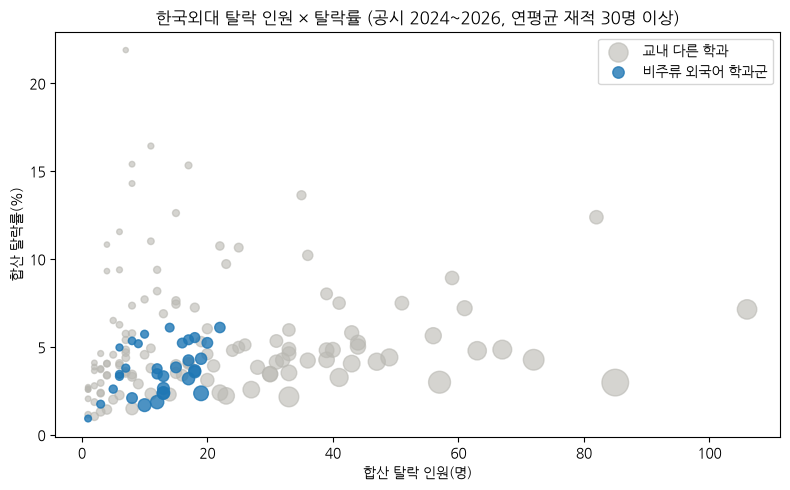

In [17]:
ok_r = r1[~r1['해석불가']]
tgt = H.groupby('학과코드')['target'].max().reindex(ok_r.index)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(ok_r.loc[~tgt, '탈락합'], ok_r.loc[~tgt, '비율'], s=ok_r.loc[~tgt, '재적합'] / 8 + 10, alpha=0.6, color='#b9b8b2', label='교내 다른 학과')
ax.scatter(ok_r.loc[tgt, '탈락합'], ok_r.loc[tgt, '비율'], s=ok_r.loc[tgt, '재적합'] / 8 + 10, alpha=0.8, color='tab:blue', label='비주류 외국어 학과군')
ax.set_xlabel('합산 탈락 인원(명)'); ax.set_ylabel('합산 탈락률(%)')
ax.set_title(f'한국외대 탈락 인원 × 탈락률 (공시 2024~2026, 연평균 재적 {MIN_ENROLL}명 이상)'); ax.legend()
fig.tight_layout(); plt.show()

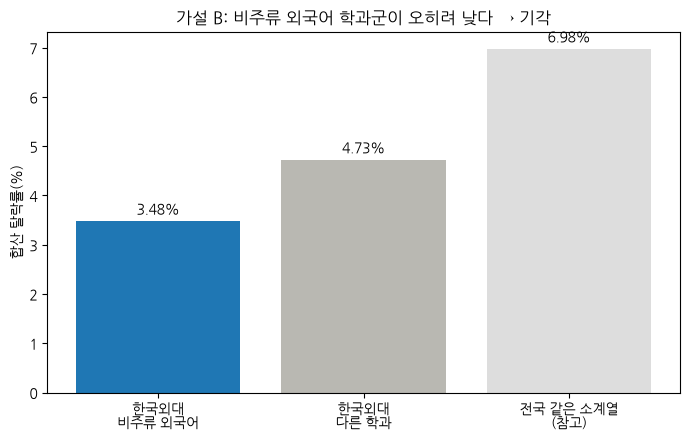

In [18]:
grp = [('한국외대\n비주류 외국어', A_), ('한국외대\n다른 학과', B_), ('전국 같은 소계열\n(참고)', NAT)]
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, (lab, g) in enumerate(grp):
    v = pooled(g); ax.bar(i, v, color=['tab:blue', '#b9b8b2', '#dddddd'][i]); ax.text(i, v + 0.15, f'{v:.2f}%', ha='center')
ax.set_xticks(range(3), [x[0] for x in grp]); ax.set_ylabel('합산 탈락률(%)'); ax.set_title(f'가설 B: 비주류 외국어 학과군이 오히려 낮다 → {verdict_B}')
fig.tight_layout(); plt.show()

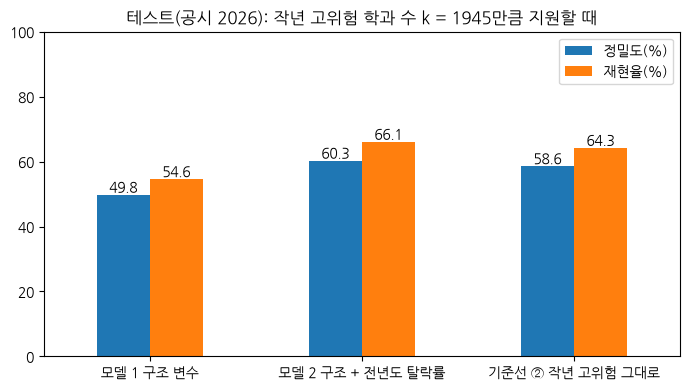

In [19]:
ax = res.set_index('방법')[['정밀도(%)', '재현율(%)']].plot.bar(figsize=(7, 4), rot=0)
ax.set_ylim(0, 100); ax.set_xlabel(''); ax.set_title(f'테스트(공시 2026): 작년 고위험 학과 수 k = {K}만큼 지원할 때')
for c in ax.containers: ax.bar_label(c, fmt='%.1f')
plt.tight_layout(); plt.show()

In [20]:
log_df = pd.DataFrame(clean_log)
log_df

,처리,건수,근거,영향
0,"완전 중복, 키 중복 확인",0,"(공시연도, 학교코드, 학과코드) 기준",처리 없음
1,재적 0 표시,2500,"분모 0으로 비율 정의 불가. 그중 1,697행은 공시 비율이 0.0으로 기록",y로 쓰지 않음(행은 유지)
2,공시 비율 vs 재계산 비교,0,최대 차이 0.005%p(반올림 수준),공시 비율 사용(팀 결정 2026-11-11)
3,비율 100% 초과 표시,172,87%가 재적 5명 이하,값 수정 없이 최소 재적 기준으로 통제
4,사유 합 = 계 확인,0,불일치 0행,처리 없음
5,기준연도 = 공시연도 표시,519,대부분은 기준연도 = 공시연도 - 1. 원인 미확인,"유지, 표시"
6,"분석 범위: 대학교, 주간, 일반과정, 폐교 제외",6259,팀 결정(가설 문서 2절),"남은 행 50,081"
7,전년 → 당해 쌍 구성 (두 해 모두 범위 안),32006,"같은 학교코드, 학과코드가 연속 공시연도에 존재",필터 적용 전
8,당해 비율 유효하지 않음 제외,4690,가설 문서 4절 사전 고정 기준,"남은 쌍 27,316"
9,전년 비율 유효하지 않음 제외,1449,가설 문서 4절 사전 고정 기준,"남은 쌍 25,867"
